# Финальный проект

# Прогнозирование лесных пожаров

Бинарная классификация

In [1]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
from IPython.core.pylabtools import figsize

In [2]:
from math import log10

Загрузим файлы во временное хранилище Colab

[train](https://disk.yandex.ru/d/F3K6ipkcWUx-FA)


[test](https://disk.yandex.ru/d/vLCRvegxsukmig)


In [3]:
df = pd.read_csv('train.csv')
df

,day,month,year,Temperature,RH,Ws,Rain,FFMC,DMC,DC,ISI,BUI,FWI,Classes
0,6,7,2012,35,42,15,0.3,84.7,15.5,45.1,4.3,16.7,6.3,1.0
1,12,8,2012,35,51,13,0.3,81.3,15.6,75.1,2.5,20.7,4.2,0.0
2,27,6,2012,34,53,18,0.0,89.0,21.6,80.3,9.2,25.8,15.0,1.0
3,18,7,2012,31,68,14,0.0,85.4,12.1,43.1,4.6,14.2,6.0,1.0
4,25,7,2012,39,64,9,1.2,73.8,11.7,15.9,1.1,11.4,0.7,0.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
191,16,8,2012,36,61,18,0.3,80.2,11.7,90.4,2.8,17.6,4.2,1.0
192,10,8,2012,39,39,15,0.2,89.3,15.8,35.4,8.2,15.8,10.7,1.0
193,4,7,2012,34,58,18,0.0,88.0,13.6,36.8,8.0,14.1,9.9,1.0
194,14,7,2012,34,61,13,0.6,73.9,7.8,22.9,1.4,8.4,0.8,0.0


In [4]:
pr_df = pd.read_csv('test.csv',)
pr_df.head()

,ID,day,month,year,Temperature,RH,Ws,Rain,FFMC,DMC,DC,ISI,BUI,FWI
0,1,2,6,2012,29,61,13,1.3,64.4,4.1,7.6,1.0,3.9,0.4
1,2,5,6,2012,27,77,16,0.0,64.8,3.0,14.2,1.2,3.9,0.5
2,3,7,6,2012,33,54,13,0.0,88.2,9.9,30.5,6.4,10.9,7.2
3,4,6,7,2012,32,63,14,0.0,87.0,10.9,37.0,5.6,12.5,6.8
4,5,10,7,2012,33,69,13,0.7,66.6,6.0,9.3,1.1,5.8,0.5


In [5]:
pr_df = pr_df.set_index('ID')

#Необходимо предсказать класс пожароопасности "Да" или "Нет". 

Показатели RH, Ws, Rain, FFMC, DMC, DC, ISI, BUI, FWI соответственно означают:


*   RН - (relative humidity);
*   Ws - (wind speed) скорость ветра;
*   Rain - количество осадков;
*   FFMC - (fine fuel moisture code) от 0 до 101, показатель увлажнённости горючих материалов подстилки под лесным пологом, временной промежуток - 16 часов;
*   DMC - (duff moisture code) увлажнённость горючих материалов слоя разложения или торфяного слоя органического происхождения под лесной подстилкой, временной промежуток - 15 дней;
*   DC - (drought code) показатель сухости;
*   ISI - (initial spread index) суммирует показатели горючести с показателями ветра и прогнозирует скорость или масштабы распространения пожара;
*   BUI - (buildup index) объединяет показатели DMC и DC для оценивания потенциального уровня жара тяжелого горючего;
*   FWI - (fire weather index) - суммирующий показатель интенсивности потенциального пожара

## Подготовка данных

In [6]:
df.columns

Index(['day', 'month', 'year', 'Temperature', ' RH', ' Ws', 'Rain ', 'FFMC',
       'DMC', 'DC', 'ISI', 'BUI', 'FWI', 'Classes  '],
      dtype='object')

In [7]:
pr_df.columns

Index(['day', 'month', 'year', 'Temperature', ' RH', ' Ws', 'Rain ', 'FFMC',
       'DMC', 'DC', 'ISI', 'BUI', 'FWI'],
      dtype='object')

In [8]:
# избавимся от пробелов в названиях столбцов
df = df.rename(columns={'Classes  ': 'Classes', ' RH': 'RH', ' Ws': 'Ws', 'Rain ': 'Rain'})
df.head()

,day,month,year,Temperature,RH,Ws,Rain,FFMC,DMC,DC,ISI,BUI,FWI,Classes
0,6,7,2012,35,42,15,0.3,84.7,15.5,45.1,4.3,16.7,6.3,1.0
1,12,8,2012,35,51,13,0.3,81.3,15.6,75.1,2.5,20.7,4.2,0.0
2,27,6,2012,34,53,18,0.0,89.0,21.6,80.3,9.2,25.8,15.0,1.0
3,18,7,2012,31,68,14,0.0,85.4,12.1,43.1,4.6,14.2,6.0,1.0
4,25,7,2012,39,64,9,1.2,73.8,11.7,15.9,1.1,11.4,0.7,0.0


In [9]:
pr_df = pr_df.rename(columns={' RH': 'RH', ' Ws': 'Ws', 'Rain ': 'Rain'})
pr_df.head()

,day,month,year,Temperature,RH,Ws,Rain,FFMC,DMC,DC,ISI,BUI,FWI
ID,,,,,,,,,,,,,
1,2,6,2012,29,61,13,1.3,64.4,4.1,7.6,1.0,3.9,0.4
2,5,6,2012,27,77,16,0.0,64.8,3.0,14.2,1.2,3.9,0.5
3,7,6,2012,33,54,13,0.0,88.2,9.9,30.5,6.4,10.9,7.2
4,6,7,2012,32,63,14,0.0,87.0,10.9,37.0,5.6,12.5,6.8
5,10,7,2012,33,69,13,0.7,66.6,6.0,9.3,1.1,5.8,0.5


In [10]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 196 entries, 0 to 195
Data columns (total 14 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   day          196 non-null    int64  
 1   month        196 non-null    int64  
 2   year         196 non-null    int64  
 3   Temperature  196 non-null    int64  
 4   RH           196 non-null    int64  
 5   Ws           196 non-null    int64  
 6   Rain         196 non-null    float64
 7   FFMC         196 non-null    float64
 8   DMC          196 non-null    float64
 9   DC           196 non-null    object 
 10  ISI          196 non-null    float64
 11  BUI          196 non-null    float64
 12  FWI          196 non-null    float64
 13  Classes      195 non-null    float64
dtypes: float64(7), int64(6), object(1)
memory usage: 21.6+ KB


In [11]:
df = df.dropna()

In [12]:
# посмотрим на наш таргет
df['Classes'].value_counts()

1.0    112
0.0     83
Name: Classes, dtype: int64

Данные довольно сбалансированы, 57 и 43%. Не нужно применять stratify

In [13]:
# посмотрим на разбивку данных по месяцам
df['month'].value_counts()

7    53
8    51
6    50
9    41
Name: month, dtype: int64

In [14]:
# посмотрим, почему в каждом месяце данных более 30
df.sort_values(by = ['month', 'day']).reset_index(drop=True)


,day,month,year,Temperature,RH,Ws,Rain,FFMC,DMC,DC,ISI,BUI,FWI,Classes
0,1,6,2012,29,57,18,0.0,65.7,3.4,7.6,1.3,3.4,0.5,0.0
1,2,6,2012,30,73,13,4.0,55.7,2.7,7.8,0.6,2.9,0.2,0.0
2,3,6,2012,29,80,14,2.0,48.7,2.2,7.6,0.3,2.6,0.1,0.0
3,3,6,2012,26,82,22,13.1,47.1,2.5,7.1,0.3,2.7,0.1,0.0
4,4,6,2012,30,64,14,0.0,79.4,5.2,15.4,2.2,5.6,1.0,0.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
190,27,9,2012,28,87,15,4.4,41.1,6.5,8,0.1,6.2,0.0,0.0
191,28,9,2012,32,47,14,0.7,77.5,7.1,8.8,1.8,6.8,0.9,0.0
192,28,9,2012,27,87,29,0.5,45.9,3.5,7.9,0.4,3.4,0.2,0.0
193,29,9,2012,24,54,18,0.1,79.7,4.3,15.2,1.7,5.1,0.7,0.0


Это значит, что в некоторые дни данные снимались дважды в день

Text(0.5, 0, 'Месяц')

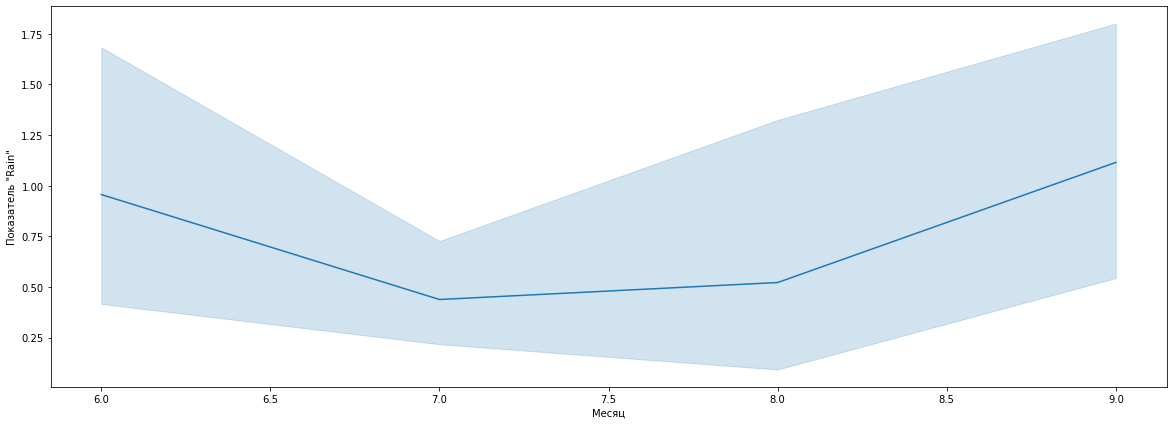

In [15]:
figsize(20, 7)
sns.lineplot(y = df['Rain'], x = df['month'])

plt.ylabel('Показатель "Rain"')
plt.xlabel('Месяц')

Text(0.5, 0, 'Месяц')

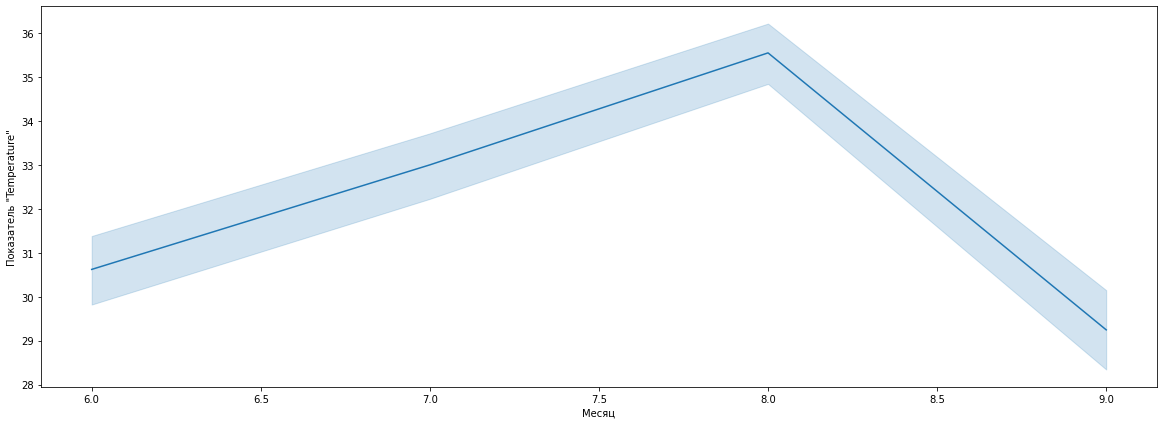

In [17]:
sns.lineplot(y = df['Temperature'], x = df['month'])

plt.ylabel('Показатель "Temperature"')
plt.xlabel('Месяц')

In [16]:
df['DC'] = df['DC'].astype(float)

<AxesSubplot:>

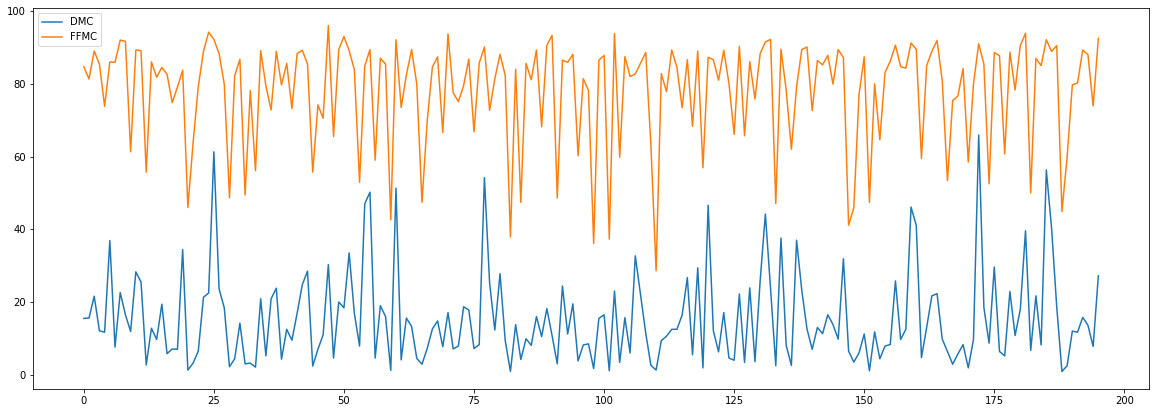

In [19]:
df.plot(y = ['DMC', 'FFMC'])

Это график показателей двух разных влажностей - краткосрочной увлажненности горючих лесных материалов под пологом и более долгосрочной влажности горючих материалов более глубокого слоя

## Сортировка по датам

Строковый формат день, месяц, год нужен для использования этих столбцов в качестве параметров модели 

In [17]:
df1 = df.copy()

In [18]:
df1['Classes'] = df1['Classes'].astype(bool)

In [19]:
df1['day'] = df1['day'].astype(str)

In [20]:
df1['month'] = df1['month'].astype(str)

In [21]:
df1['year'] = df1['year'].astype(str)

In [22]:
df1

,day,month,year,Temperature,RH,Ws,Rain,FFMC,DMC,DC,ISI,BUI,FWI,Classes
0,6,7,2012,35,42,15,0.3,84.7,15.5,45.1,4.3,16.7,6.3,True
1,12,8,2012,35,51,13,0.3,81.3,15.6,75.1,2.5,20.7,4.2,False
2,27,6,2012,34,53,18,0.0,89.0,21.6,80.3,9.2,25.8,15.0,True
3,18,7,2012,31,68,14,0.0,85.4,12.1,43.1,4.6,14.2,6.0,True
4,25,7,2012,39,64,9,1.2,73.8,11.7,15.9,1.1,11.4,0.7,False
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
191,16,8,2012,36,61,18,0.3,80.2,11.7,90.4,2.8,17.6,4.2,True
192,10,8,2012,39,39,15,0.2,89.3,15.8,35.4,8.2,15.8,10.7,True
193,4,7,2012,34,58,18,0.0,88.0,13.6,36.8,8.0,14.1,9.9,True
194,14,7,2012,34,61,13,0.6,73.9,7.8,22.9,1.4,8.4,0.8,False


In [23]:
df1['date'] = (df1['year']) + (df1['month']) + (df1['day'])

In [24]:
df1['date'] = pd.to_datetime(df1['date'], format='%Y%m%d')

In [25]:
df1.info()

<class 'pandas.core.frame.DataFrame'>
Int64Index: 195 entries, 0 to 195
Data columns (total 15 columns):
 #   Column       Non-Null Count  Dtype         
---  ------       --------------  -----         
 0   day          195 non-null    object        
 1   month        195 non-null    object        
 2   year         195 non-null    object        
 3   Temperature  195 non-null    int64         
 4   RH           195 non-null    int64         
 5   Ws           195 non-null    int64         
 6   Rain         195 non-null    float64       
 7   FFMC         195 non-null    float64       
 8   DMC          195 non-null    float64       
 9   DC           195 non-null    float64       
 10  ISI          195 non-null    float64       
 11  BUI          195 non-null    float64       
 12  FWI          195 non-null    float64       
 13  Classes      195 non-null    bool          
 14  date         195 non-null    datetime64[ns]
dtypes: bool(1), datetime64[ns](1), float64(7), int64(3), obje

In [26]:
df1 = df1.drop(columns = ['day', 'month', 'year'])
df1

,Temperature,RH,Ws,Rain,FFMC,DMC,DC,ISI,BUI,FWI,Classes,date
0,35,42,15,0.3,84.7,15.5,45.1,4.3,16.7,6.3,True,2012-07-06
1,35,51,13,0.3,81.3,15.6,75.1,2.5,20.7,4.2,False,2012-08-12
2,34,53,18,0.0,89.0,21.6,80.3,9.2,25.8,15.0,True,2012-06-27
3,31,68,14,0.0,85.4,12.1,43.1,4.6,14.2,6.0,True,2012-07-18
4,39,64,9,1.2,73.8,11.7,15.9,1.1,11.4,0.7,False,2012-07-25
...,...,...,...,...,...,...,...,...,...,...,...,...
191,36,61,18,0.3,80.2,11.7,90.4,2.8,17.6,4.2,True,2012-08-16
192,39,39,15,0.2,89.3,15.8,35.4,8.2,15.8,10.7,True,2012-08-10
193,34,58,18,0.0,88.0,13.6,36.8,8.0,14.1,9.9,True,2012-07-04
194,34,61,13,0.6,73.9,7.8,22.9,1.4,8.4,0.8,False,2012-07-14


Text(0.5, 0, 'Дата')

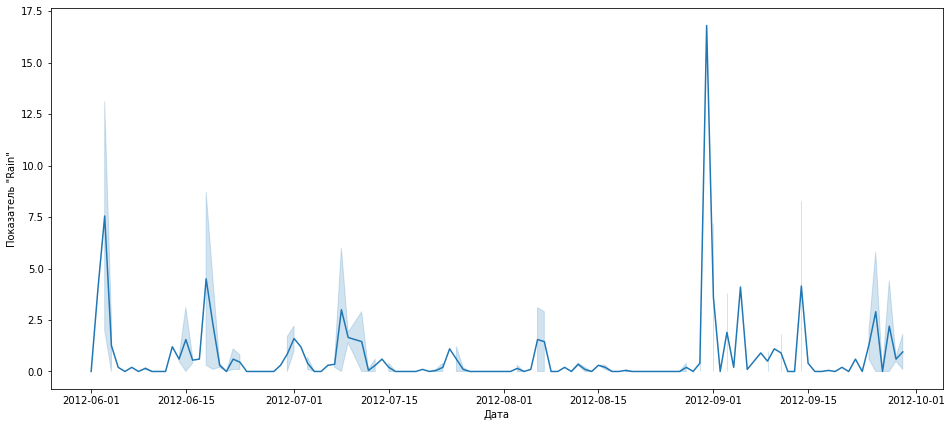

In [30]:
figsize(16, 7)
sns.lineplot(x = df1['date'], y = df1['Rain'])

plt.ylabel('Показатель "Rain"')
plt.xlabel('Дата')
# теперь можно посмотреть на осадки по датам

Text(0.5, 0, 'Дата')

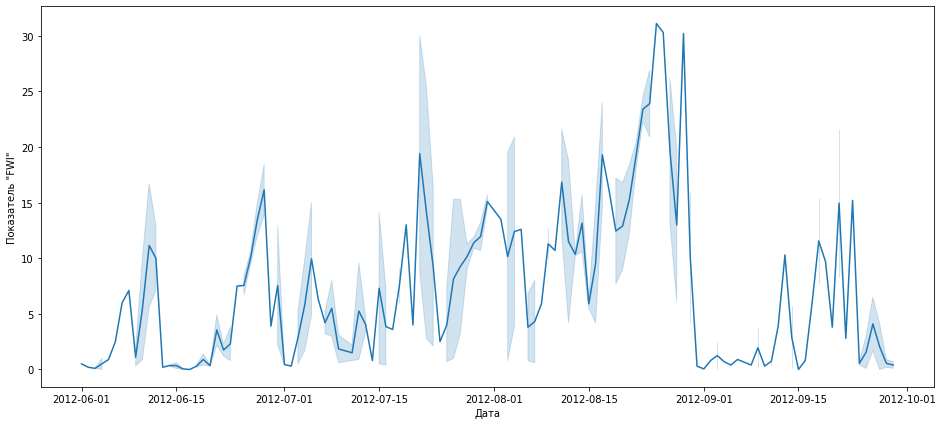

In [31]:
figsize(16, 7)
sns.lineplot(y = df1['FWI'], x = df1['date'])

plt.ylabel('Показатель "FWI"')
plt.xlabel('Дата')

Text(0.5, 0, 'Дата')

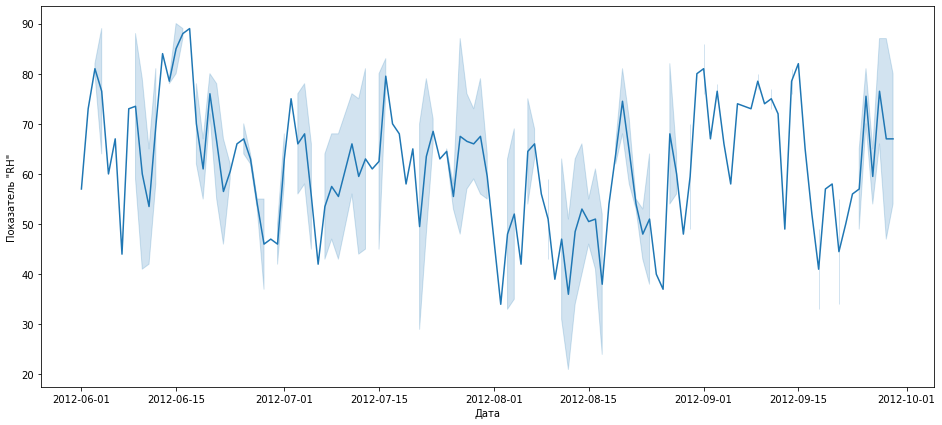

In [32]:
figsize(16, 7)
sns.lineplot(y = df1['RH'], x = df1['date'])

plt.ylabel('Показатель "RH"')
plt.xlabel('Дата')

In [33]:
df.info()

<class 'pandas.core.frame.DataFrame'>
Int64Index: 195 entries, 0 to 195
Data columns (total 14 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   day          195 non-null    int64  
 1   month        195 non-null    int64  
 2   year         195 non-null    int64  
 3   Temperature  195 non-null    int64  
 4   RH           195 non-null    int64  
 5   Ws           195 non-null    int64  
 6   Rain         195 non-null    float64
 7   FFMC         195 non-null    float64
 8   DMC          195 non-null    float64
 9   DC           195 non-null    float64
 10  ISI          195 non-null    float64
 11  BUI          195 non-null    float64
 12  FWI          195 non-null    float64
 13  Classes      195 non-null    float64
dtypes: float64(8), int64(6)
memory usage: 26.9 KB


<AxesSubplot:>

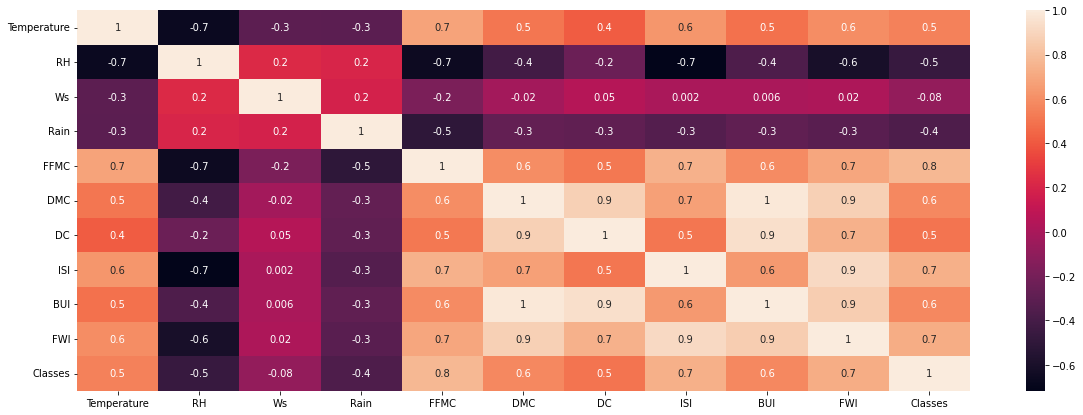

In [27]:
# посмотрим на хитмэп корреляции признаков

sns.heatmap(df1.corr(), annot = True, fmt='.1g')


Матрица корреляции показывает много коррелирующих признаков. Например, DMC и BUI полностью коррелируют, можно оставить только один из них. На 0,9 коррелируют DMC и DC, DMC и FWI, FWI с ISI и BUI.

## Модель

In [28]:
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.linear_model import SGDClassifier

from sklearn import tree
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder

from sklearn.metrics import mean_squared_error
from sklearn.metrics import accuracy_score
from sklearn.metrics import roc_auc_score

In [29]:
# определим таргет
X = df.drop(columns=["Classes", "year", "BUI"])
y = df["Classes"]

# разделим на тренировочную и тестовую выборки
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=47)

### Logistic Regression

In [30]:
model_lr = LogisticRegression()

# Обучим модель
model_lr.fit(X_train, y_train)

/usr/local/lib/python3.8/dist-packages/sklearn/linear_model/_logistic.py:458: ConvergenceWarning: lbfgs failed to converge (status=1):
STOP: TOTAL NO. of ITERATIONS REACHED LIMIT.

Increase the number of iterations (max_iter) or scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(


LogisticRegression()

In [31]:
y_pred_test_lr = model_lr.predict(X_test)

In [ ]:
print(y_pred_test_lr)
print(y_test)

In [33]:
# Посмотрим на метрики ошибки MSE, ROC AUC, Accuracy score

print("MSE: ", mean_squared_error(y_test, y_pred_test_lr))
print("ROC_AUC: ", roc_auc_score(y_test, y_pred_test_lr))
print("Accuracy: ", accuracy_score(y_test, y_pred_test_lr))

MSE:  0.05128205128205128
ROC_AUC:  0.9458333333333334
Accuracy:  0.9487179487179487


### KNN

In [34]:
# сравним с kNN

model_knn = KNeighborsClassifier(n_neighbors=3, weights='distance', algorithm='auto', leaf_size=5)

model_knn.fit(X_train, y_train)
y_predict_knn = model_knn.predict(X_test)
# проверим среднюю квадратичную ошибку
print("MSE: ", mean_squared_error(y_test, y_predict_knn))
print("Accuracy: ", accuracy_score(y_test, y_predict_knn))

MSE:  0.1282051282051282
Accuracy:  0.8717948717948718


### Decision Tree

In [35]:
model_tree = tree.DecisionTreeClassifier()


In [36]:
# Обучим модель
model_tree.fit(X_train, y_train)

DecisionTreeClassifier()

[Text(0.6, 0.9, 'x[9] <= 3.05\ngini = 0.492\nsamples = 156\nvalue = [68, 88]'),
 Text(0.4, 0.7, 'x[6] <= 80.15\ngini = 0.081\nsamples = 71\nvalue = [68, 3]'),
 Text(0.2, 0.5, 'gini = 0.0\nsamples = 65\nvalue = [65, 0]'),
 Text(0.6, 0.5, 'x[5] <= 0.05\ngini = 0.5\nsamples = 6\nvalue = [3, 3]'),
 Text(0.4, 0.3, 'x[2] <= 30.5\ngini = 0.375\nsamples = 4\nvalue = [3, 1]'),
 Text(0.2, 0.1, 'gini = 0.0\nsamples = 1\nvalue = [0, 1]'),
 Text(0.6, 0.1, 'gini = 0.0\nsamples = 3\nvalue = [3, 0]'),
 Text(0.8, 0.3, 'gini = 0.0\nsamples = 2\nvalue = [0, 2]'),
 Text(0.8, 0.7, 'gini = 0.0\nsamples = 85\nvalue = [0, 85]')]

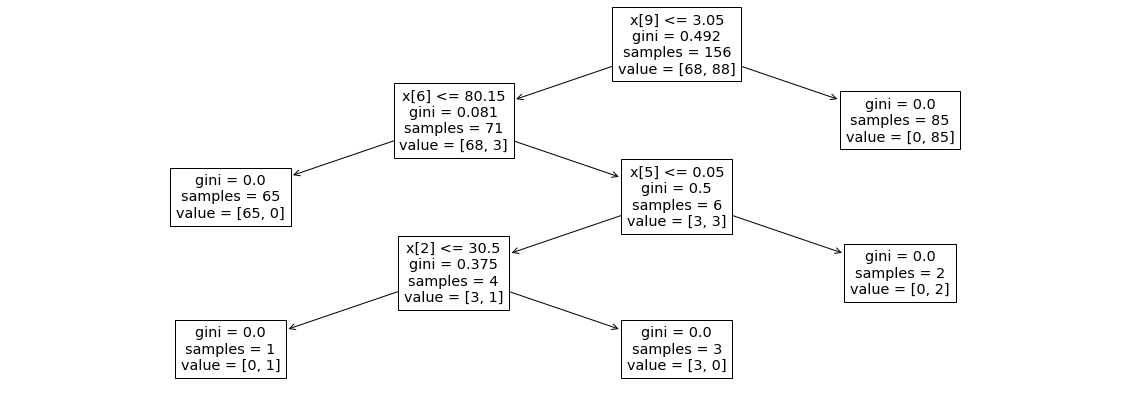

In [37]:
tree.plot_tree(model_tree)

In [38]:
y_predict_tree = model_tree.predict(X_test)

In [39]:
# Посмотрим на метрики ошибки MSE, ROC AUC, Accuracy score дерева решений

print("Tree MSE: ", mean_squared_error(y_test, y_predict_tree))
print("Tree ROC_AUC: ", roc_auc_score(y_test, y_predict_tree))
print("Tree Accuracy: ", accuracy_score(y_test, y_predict_tree))

Tree MSE:  0.02564102564102564
Tree ROC_AUC:  0.9666666666666667
Tree Accuracy:  0.9743589743589743


In [42]:
print("Логистическая регрессия MSE:      ", mean_squared_error(y_test, y_pred_test_lr))
print("Логистическая регрессия ROC_AUC:  ", roc_auc_score(y_test, y_pred_test_lr))
print("Логистическая регрессия Accuracy: ", accuracy_score(y_test, y_pred_test_lr))
print()
print("Метод ближайших соседей MSE:      ", mean_squared_error(y_test, y_predict_knn))
print("Метод ближайших соседей ROC_AUC:  ", roc_auc_score(y_test, y_predict_knn))
print("Метод ближайших соседей Accuracy: ", accuracy_score(y_test, y_predict_knn))
print()
print("Дерево решений MSE:               ", mean_squared_error(y_test, y_predict_tree))
print("Дерево решений ROC_AUC:           ", roc_auc_score(y_test, y_predict_tree))
print("Дерево решений Accuracy:          ", accuracy_score(y_test, y_predict_tree))

Логистическая регрессия MSE:       0.05128205128205128
Логистическая регрессия ROC_AUC:   0.9458333333333334
Логистическая регрессия Accuracy:  0.9487179487179487

Метод ближайших соседей MSE:       0.1282051282051282
Метод ближайших соседей ROC_AUC:   0.8583333333333333
Метод ближайших соседей Accuracy:  0.8717948717948718

Дерево решений MSE:                0.02564102564102564
Дерево решений ROC_AUC:            0.9666666666666667
Дерево решений Accuracy:           0.9743589743589743


### Работа моделей с подбором параметров

### Random Forest

In [43]:
from sklearn.ensemble import RandomForestClassifier

rf = RandomForestClassifier()

In [44]:
grid_space={'max_depth':[3,5,10,None],
              'n_estimators':[10,50,100],
              'max_features':[1,3,5,7],
              'min_samples_leaf':[1,2,3],
              'min_samples_split':[1,2,3]
           }

In [45]:
from sklearn.model_selection import GridSearchCV

grid = GridSearchCV(rf,param_grid=grid_space,cv=3,scoring='roc_auc')
model_grid = grid.fit(X,y)

In [47]:
print('Best hyperparameters are: '+str(model_grid.best_params_))
print('Best score is: '+str(model_grid.best_score_))

Best hyperparameters are: {'max_depth': 3, 'max_features': 3, 'min_samples_leaf': 3, 'min_samples_split': 2, 'n_estimators': 10}
Best score is: 0.9996782496782496


In [48]:
y_predict_rf = model_grid.predict(X_test)

In [49]:
print("Random Forest Accuracy: ", accuracy_score(y_test, y_predict_rf))
print("Random Forest ROC_AUC: ", roc_auc_score(y_test, y_predict_rf))

Random Forest Accuracy:  1.0
Random Forest ROC_AUC:  1.0


### SGD

In [46]:
sgd = SGDClassifier()

In [50]:
grid_space_sgd={'max_iter':[500,1000,3000],
              'tol':[0.1,0.001,0.0001],
              'random_state':[None,13,47,150],
              'verbose':[0,1]
           }

In [51]:
grid_sgd = GridSearchCV(sgd,param_grid=grid_space_sgd,cv=5,scoring='roc_auc')
model_grid_sgd = grid_sgd.fit(X,y)

Выходные данные были обрезаны до нескольких последних строк (5000).
Norm: 4137.23, NNZs: 11, Bias: -58.485762, T: 936, Avg. loss: 5219.156632
Total training time: 0.01 seconds.
-- Epoch 7
Norm: 4100.02, NNZs: 11, Bias: -63.502096, T: 1092, Avg. loss: 4878.017529
Total training time: 0.01 seconds.
-- Epoch 8
Norm: 4147.68, NNZs: 11, Bias: -68.129464, T: 1248, Avg. loss: 4864.556646
Total training time: 0.01 seconds.
-- Epoch 9
Norm: 4198.93, NNZs: 11, Bias: -76.664005, T: 1404, Avg. loss: 5887.963415
Total training time: 0.01 seconds.
-- Epoch 10
Norm: 4158.87, NNZs: 11, Bias: -80.674374, T: 1560, Avg. loss: 3778.552663
Total training time: 0.01 seconds.
-- Epoch 11
Norm: 4055.11, NNZs: 11, Bias: -84.429135, T: 1716, Avg. loss: 3433.151782
Total training time: 0.01 seconds.
-- Epoch 12
Norm: 4006.27, NNZs: 11, Bias: -88.028631, T: 1872, Avg. loss: 2797.652282
Total training time: 0.02 seconds.
-- Epoch 13
Norm: 3909.35, NNZs: 11, Bias: -91.384530, T: 2028, Avg. loss: 2451.636159
Total t

In [52]:
print('Best hyperparameters are: '+str(model_grid_sgd.best_params_))
print('Best score is: '+str(model_grid_sgd.best_score_))

Best hyperparameters are: {'max_iter': 500, 'random_state': None, 'tol': 0.001, 'verbose': 0}
Best score is: 0.9870611485701


In [53]:
y_predict_sgd = model_grid_sgd.predict(X_test)

In [54]:
print("SGD Classifier Accuracy: ", accuracy_score(y_test, y_predict_sgd))
print("SGD  Classifier ROC_AUC: ", roc_auc_score(y_test, y_predict_sgd))

SGD Classifier Accuracy:  0.7948717948717948
SGD  Classifier ROC_AUC:  0.7333333333333334


In [102]:
print("Random Forest Accuracy: ", accuracy_score(y_test, y_predict_rf))
print("Random Forest ROC_AUC: ", roc_auc_score(y_test, y_predict_rf))
print()
print("SGD Classifier Accuracy: ", accuracy_score(y_test, y_predict_sgd))
print("SGD  Classifier ROC_AUC: ", roc_auc_score(y_test, y_predict_sgd))

Random Forest Accuracy:  1.0
Random Forest ROC_AUC:  1.0

SGD Classifier Accuracy:  0.7948717948717948
SGD  Classifier ROC_AUC:  0.7333333333333334


SGD Classifier сработал хуже всех. Модель KNN показала себя хуже логистической регресии. Дерево решений справилось лучше логистической регрессии и метода ближайших соседей. Метод случайного леса с подбором параметров показал себя отлично



### Масштабирование и нормализация данных



In [55]:
from sklearn.metrics import f1_score
from sklearn import preprocessing
from sklearn.preprocessing import StandardScaler


X_train_norm, X_valid_norm, y_train, y_valid = train_test_split(X, y, test_size=0.25, random_state=13)

scaler = StandardScaler()

In [56]:
scaler.fit(X_train_norm, y_train)

StandardScaler()

In [57]:
# трансформируем обратно
X_train_norm_sc = pd.DataFrame(scaler.transform(X_train_norm))
X_valid_norm_sc = pd.DataFrame(scaler.transform(X_valid_norm))

In [58]:
# Построим линейную модель с масштабированными данными
model_lc_sc = LogisticRegression()
model_lc_sc.fit(X_train_norm_sc, y_train)
y_predict_lc_1 = model_lc_sc.predict(X_train_norm_sc)
y_pred_test_lc_1 = model_lc_sc.predict(X_valid_norm_sc)

# посмотрим ошибки r2 и MSE
print("R2: ", f1_score(y_valid, y_pred_test_lc_1))
print("MSE: ", mean_squared_error(y_valid, y_pred_test_lc_1))
print("ROC_AUC: ", roc_auc_score(y_valid, y_pred_test_lc_1))
print("Accuracy: ", accuracy_score(y_valid, y_pred_test_lc_1))

R2:  0.9454545454545454
MSE:  0.061224489795918366
ROC_AUC:  0.9482758620689655
Accuracy:  0.9387755102040817


Ошибки показали незначительное ухудшение работы модели после применения Standard Scaler



> Посмотрим на работу с другим инструментом масштабирования



In [59]:
from sklearn.preprocessing import MinMaxScaler

Xr_train_norm, Xr_valid_norm, yr_train, yr_valid = train_test_split(X, y, test_size=0.2, random_state=13)

scaler = MinMaxScaler()

In [60]:
scaler.fit(Xr_train_norm, yr_train)

MinMaxScaler()

In [61]:
# трансформируем обратно
X_train_norm_scr = pd.DataFrame(scaler.transform(Xr_train_norm))
X_valid_norm_scr = pd.DataFrame(scaler.transform(Xr_valid_norm))

In [62]:
# Построим линейную модель с масштабированными данными MinMaxScaler
model_lc_scr = LogisticRegression()
model_lc_scr.fit(X_train_norm_scr, yr_train)
y_predict_lc_r = model_lc_scr.predict(X_train_norm_scr)
y_pred_test_lc_r = model_lc_scr.predict(X_valid_norm_scr)

# посмотрим ошибки r2 и MSE
print("R2: ", f1_score(yr_valid, y_pred_test_lc_r))
print("MSE: ", mean_squared_error(yr_valid, y_pred_test_lc_r))
print("ROC_AUC: ", roc_auc_score(yr_valid, y_pred_test_lc_r))
print("Accuracy: ", accuracy_score(yr_valid, y_pred_test_lc_r))

R2:  0.9433962264150944
MSE:  0.07692307692307693
ROC_AUC:  0.9212962962962963
Accuracy:  0.9230769230769231


Получается предпочтительнее модель дерева решений, случайного леса или SGD с подбором гиперпараметров

In [66]:
X_test.shape

(39, 11)

In [67]:
y_test.shape

(39,)

In [ ]:
y_test

<AxesSubplot:xlabel='Classes', ylabel='Count'>

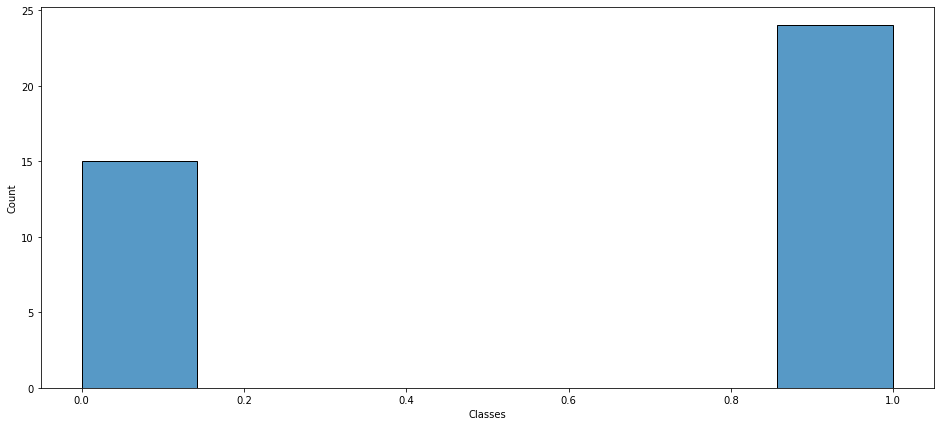

In [69]:
# график предсказания на тесте
sns.histplot(y_test)

<AxesSubplot:ylabel='Count'>

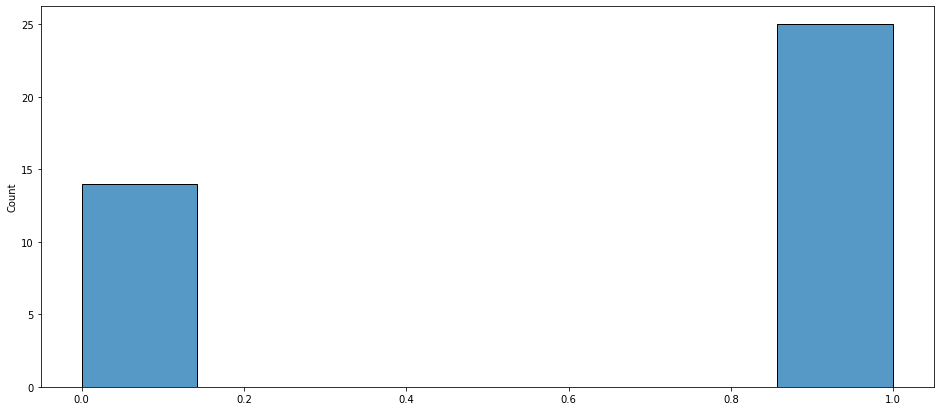

In [70]:
sns.histplot(y_predict_tree)

<AxesSubplot:ylabel='Count'>

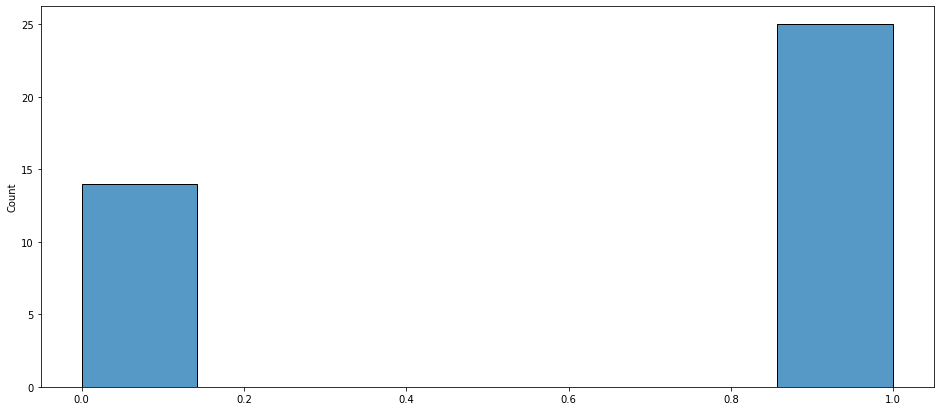

In [71]:
sns.histplot(y_predict_knn)

# Рассмотрим российскую систему прогнозирования пожароопасности
В более доступной и лёгкой в расчётах формуле для этого используется меньше показателей и 5 классов пожароопасности

Точка росы вычисляется по формуле:

$$Tp = (b * f) / (a - f)$$

 $$ f = (a * T) / (b + T) + ln(Rh / 100)$$


где 
*   a - константа 17,27;
*   b - константа 237,7;
*   T - температура на 12 часов дня;
*   Rh - относительная влажность в процентах.


> Класс пожароопасности зависит от показателя КП, который расчитывается нарастающим итогом в дни, когда осадки были менее 3 мм по формуле. В дождливые дни сумма обнуляется, а формула считается как обычно. Если класс пожароопасности равнялся IV и выше, сумма не обнуляется, а делится на "2"


> $$ КП = T * (T - Tp)$$


Класс горимости / КП

*   I - полная негоримость    / менее 300    
*   II - низкая горимость     / 301-1000
*   III - средняя горимость   / 1001-4000
*   IV - высокая              / 4001-10000
*   V - чрезвычайная          / более 10000

In [63]:
df2 = df
df2


,day,month,year,Temperature,RH,Ws,Rain,FFMC,DMC,DC,ISI,BUI,FWI,Classes
0,6,7,2012,35,42,15,0.3,84.7,15.5,45.1,4.3,16.7,6.3,1.0
1,12,8,2012,35,51,13,0.3,81.3,15.6,75.1,2.5,20.7,4.2,0.0
2,27,6,2012,34,53,18,0.0,89.0,21.6,80.3,9.2,25.8,15.0,1.0
3,18,7,2012,31,68,14,0.0,85.4,12.1,43.1,4.6,14.2,6.0,1.0
4,25,7,2012,39,64,9,1.2,73.8,11.7,15.9,1.1,11.4,0.7,0.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
191,16,8,2012,36,61,18,0.3,80.2,11.7,90.4,2.8,17.6,4.2,1.0
192,10,8,2012,39,39,15,0.2,89.3,15.8,35.4,8.2,15.8,10.7,1.0
193,4,7,2012,34,58,18,0.0,88.0,13.6,36.8,8.0,14.1,9.9,1.0
194,14,7,2012,34,61,13,0.6,73.9,7.8,22.9,1.4,8.4,0.8,0.0


In [64]:
df2 = df2.drop(columns= ['ISI', 'year', 'BUI', 'FFMC', 'DMC', 'DC', 'FWI'])

In [65]:
df2.head()

,day,month,Temperature,RH,Ws,Rain,Classes
0,6,7,35,42,15,0.3,1.0
1,12,8,35,51,13,0.3,0.0
2,27,6,34,53,18,0.0,1.0
3,18,7,31,68,14,0.0,1.0
4,25,7,39,64,9,1.2,0.0


Далее преобразуем нужные столбцы в массив, чтобы вычислить показатель "Точка росы" по ранее упомянутой формуле

$$Tp = (b * f) / (a - f)$$

 $$ f = (a * T) / (b + T) + ln(Rh / 100)$$

In [66]:
tmpr = np.array(df2['Temperature'].tolist())              # нам нужна температура

In [67]:
tmpr

array([35, 35, 34, 31, 39, 36, 33, 40, 39, 26, 37, 32, 30, 34, 34, 31, 31,
       34, 31, 36, 25, 28, 30, 27, 40, 33, 34, 32, 29, 28, 31, 28, 30, 30,
       36, 30, 33, 36, 24, 33, 28, 35, 34, 31, 27, 33, 30, 42, 33, 36, 39,
       36, 35, 25, 33, 34, 30, 35, 30, 25, 35, 30, 36, 30, 31, 26, 34, 28,
       35, 32, 39, 32, 31, 34, 31, 28, 31, 35, 35, 33, 34, 36, 29, 26, 29,
       35, 33, 37, 27, 31, 40, 26, 33, 32, 34, 31, 32, 27, 29, 32, 36, 30,
       38, 30, 33, 31, 35, 29, 32, 25, 29, 31, 29, 31, 28, 32, 29, 35, 31,
       31, 30, 30, 36, 33, 30, 36, 29, 33, 29, 35, 32, 35, 26, 36, 33, 30,
       35, 35, 36, 28, 32, 39, 31, 28, 32, 35, 28, 27, 32, 37, 22, 29, 32,
       30, 32, 36, 34, 31, 36, 37, 29, 38, 35, 37, 35, 27, 28, 35, 31, 30,
       35, 36, 33, 28, 36, 31, 30, 33, 35, 34, 36, 27, 33, 34, 34, 34, 34,
       24, 29, 34, 36, 39, 34, 34, 37])

In [68]:
hum = np.array(df2['RH'].tolist())                       # нам нужна относительная влажность
hum

array([42, 51, 53, 68, 64, 71, 66, 41, 43, 49, 55, 55, 73, 70, 81, 83, 67,
       56, 67, 81, 76, 58, 73, 58, 31, 37, 42, 47, 80, 75, 64, 80, 65, 77,
       55, 64, 63, 56, 54, 68, 79, 34, 49, 79, 75, 59, 54, 24, 62, 54, 21,
       55, 46, 88, 82, 64, 78, 63, 65, 78, 38, 66, 55, 41, 55, 80, 63, 81,
       59, 68, 33, 47, 75, 58, 64, 90, 66, 48, 70, 65, 58, 43, 86, 81, 87,
       44, 76, 52, 66, 42, 34, 81, 76, 66, 59, 72, 62, 59, 89, 69, 62, 89,
       35, 80, 57, 54, 66, 49, 76, 89, 70, 50, 57, 65, 79, 73, 65, 56, 78,
       71, 73, 78, 53, 78, 58, 48, 57, 68, 74, 68, 48, 34, 82, 53, 46, 73,
       56, 62, 44, 76, 75, 45, 55, 70, 49, 64, 87, 87, 60, 56, 76, 87, 67,
       80, 55, 33, 56, 65, 43, 53, 74, 43, 63, 40, 47, 79, 67, 63, 72, 77,
       64, 54, 70, 80, 58, 52, 80, 50, 58, 45, 29, 84, 66, 69, 40, 64, 45,
       82, 68, 42, 61, 39, 58, 61, 37])

Создадим новый массив с названием "dew"

In [69]:
dew = list()

In [70]:
dew

[]

In [71]:
def Td(tr, hm, a=17.27, b=237.7):
  
  for i in tr:
    t = tr[i]
    h = hm[i]
    f = (t*a)/(t+b) + log10(h/100)
    x = round((b * f) / (a - f), 2)
    dew.append(x)

  return np.array(dew)

Функция "Td" возвращает нам заполненный массив "dew"

In [72]:
Td(tr = tmpr, hm = hum)

array([26.66, 26.66, 31.34, 26.34, 30.04, 29.46, 28.03, 26.25, 30.04,
       27.39, 31.48, 26.77, 27.63, 31.34, 31.34, 26.34, 26.34, 31.34,
       26.34, 29.46, 25.51, 27.33, 27.63, 26.31, 26.25, 28.03, 31.34,
       26.77, 25.87, 27.33, 26.34, 27.33, 27.63, 27.63, 29.46, 27.63,
       28.03, 29.46, 30.76, 28.03, 27.33, 26.66, 31.34, 26.34, 26.31,
       28.03, 27.63, 28.54, 28.03, 29.46, 30.04, 29.46, 26.66, 25.51,
       28.03, 31.34, 27.63, 26.66, 27.63, 25.51, 26.66, 27.63, 29.46,
       27.63, 26.34, 27.39, 31.34, 27.33, 26.66, 26.77, 30.04, 26.77,
       26.34, 31.34, 26.34, 27.33, 26.34, 26.66, 26.66, 28.03, 31.34,
       29.46, 25.87, 27.39, 25.87, 26.66, 28.03, 31.48, 26.31, 26.34,
       26.25, 27.39, 28.03, 26.77, 31.34, 26.34, 26.77, 26.31, 25.87,
       26.77, 29.46, 27.63, 19.61, 27.63, 28.03, 26.34, 26.66, 25.87,
       26.77, 25.51, 25.87, 26.34, 25.87, 26.34, 27.33, 26.77, 25.87,
       26.66, 26.34, 26.34, 27.63, 27.63, 29.46, 28.03, 27.63, 29.46,
       25.87, 28.03,

Создадим новый столбец нашего датасета. Позднее на тренировочном и тесте проверим правдоподобность российской классификации

In [73]:
df2['Dew point'] = dew

In [74]:
df3 = df2.sort_values(by = ['month', 'day']).reset_index(drop=True)
# для удобства просмотра данных хронологически, поменяем индексы согласно сортировке

In [75]:
df3.head()

,day,month,Temperature,RH,Ws,Rain,Classes,Dew point
0,1,6,29,57,18,0.0,0.0,25.87
1,2,6,30,73,13,4.0,0.0,27.63
2,3,6,29,80,14,2.0,0.0,25.87
3,3,6,26,82,22,13.1,0.0,27.39
4,4,6,30,64,14,0.0,0.0,27.63


In [76]:
# используем промежуточный параметр, который поможет определить класс пожароопасности
df3['k_p'] = round(df3['Temperature'] * (df3['Temperature'] - df3['Dew point']), 2)

In [77]:
df3

,day,month,Temperature,RH,Ws,Rain,Classes,Dew point,k_p
0,1,6,29,57,18,0.0,0.0,25.87,90.77
1,2,6,30,73,13,4.0,0.0,27.63,71.10
2,3,6,29,80,14,2.0,0.0,25.87,90.77
3,3,6,26,82,22,13.1,0.0,27.39,-36.14
4,4,6,30,64,14,0.0,0.0,27.63,71.10
...,...,...,...,...,...,...,...,...,...
190,27,9,28,87,15,4.4,0.0,27.33,18.76
191,28,9,32,47,14,0.7,0.0,26.77,167.36
192,28,9,27,87,29,0.5,0.0,26.31,18.63
193,29,9,24,54,18,0.1,0.0,30.76,-162.24


In [78]:
df3['low_danger'] = df3['Rain'] >= 3.0

In [79]:
df3

,day,month,Temperature,RH,Ws,Rain,Classes,Dew point,k_p,low_danger
0,1,6,29,57,18,0.0,0.0,25.87,90.77,False
1,2,6,30,73,13,4.0,0.0,27.63,71.10,True
2,3,6,29,80,14,2.0,0.0,25.87,90.77,False
3,3,6,26,82,22,13.1,0.0,27.39,-36.14,True
4,4,6,30,64,14,0.0,0.0,27.63,71.10,False
...,...,...,...,...,...,...,...,...,...,...
190,27,9,28,87,15,4.4,0.0,27.33,18.76,True
191,28,9,32,47,14,0.7,0.0,26.77,167.36,False
192,28,9,27,87,29,0.5,0.0,26.31,18.63,False
193,29,9,24,54,18,0.1,0.0,30.76,-162.24,False


In [81]:
# Просчитаем конечный показатель КП суммирующим итогом с учётом количества выпавших осадков, 
# двойного измерения в день и полученного класса пожароопасности в таблице
df3.to_excel('kp.xlsx')

## Датасет с другими параметрами

In [83]:
my_df = pd.read_excel('k_p.xlsx')

In [84]:
my_df

,day,month,Temperature,RH,Ws,Rain,Classes,Dew point,k_p,low_danger,sum_kp
0,1,6,29,57,18,0.0,0,25.87,90.77,False,90.77
1,2,6,30,73,13,4.0,0,27.63,71.10,True,71.10
2,3,6,29,80,14,2.0,0,25.87,90.77,False,162.00
3,3,6,26,82,22,13.1,0,27.39,-36.14,True,90.77
4,4,6,30,64,14,0.0,0,27.63,71.10,False,162.00
...,...,...,...,...,...,...,...,...,...,...,...
190,27,9,28,87,15,4.4,0,27.33,18.76,True,18.76
191,28,9,32,47,14,0.7,0,26.77,167.36,False,186.00
192,28,9,27,87,29,0.5,0,26.31,0.00,False,186.00
193,29,9,24,54,18,0.1,0,30.76,-162.24,False,24.00


<AxesSubplot:>

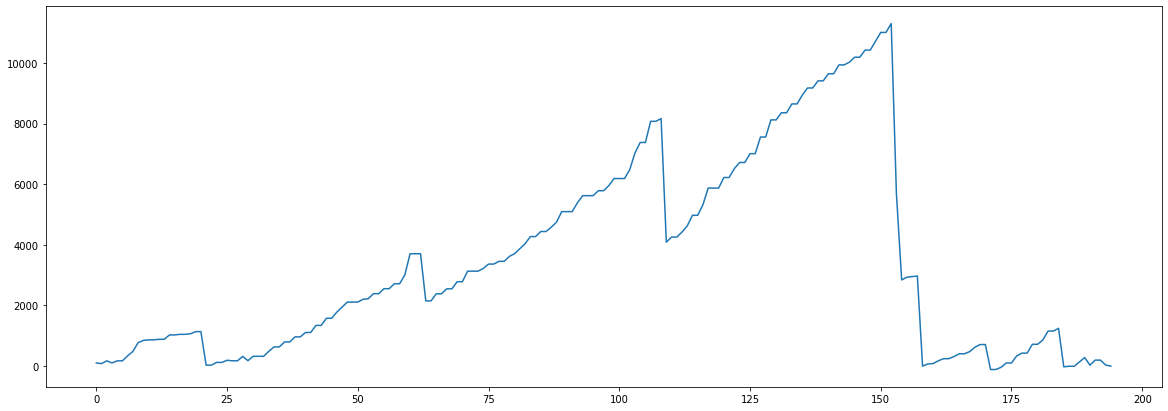

In [85]:
my_df['sum_kp'].plot()

In [86]:
my_df.sum_kp.describe()

count      195.000000
mean      3400.463846
std       3235.581747
min       -124.080000
25%        544.500000
50%       2540.000000
75%       5725.130000
max      11301.000000
Name: sum_kp, dtype: float64

## Построим модель на новых данных

<AxesSubplot:>

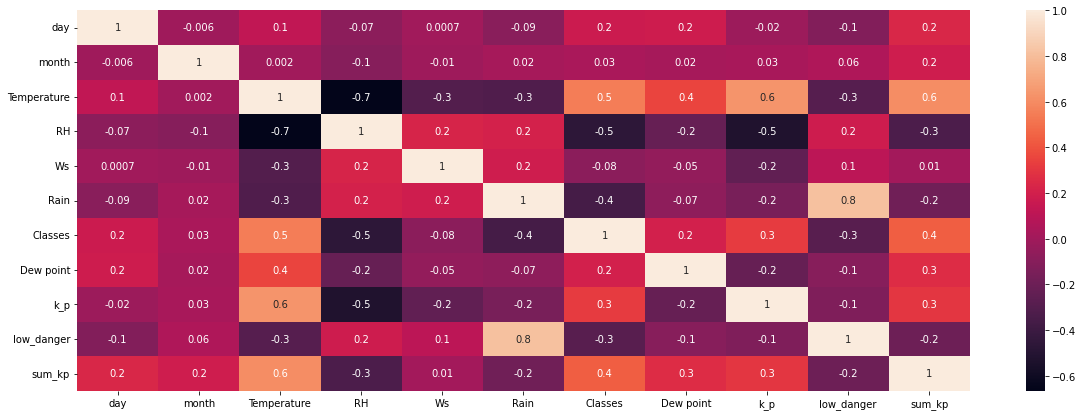

In [87]:
# посмотрим на хитмэп корреляции признаков

sns.heatmap(my_df.corr(), annot = True, fmt='.1g')

In [88]:
# определим новый таргет с урезанными данными и новыми подсчитанными
X_my = my_df.drop(columns=["Classes"])
y_my = my_df["Classes"]

# разделим на тренировочную и тестовую выборки
X_my_train, X_my_test, y_my_train, y_my_test = train_test_split(X_my, y_my, test_size=0.2, random_state=47)

### Random Forest

In [89]:
model_grid = grid.fit(X_my,y_my)

In [90]:
print('Best hyperparameters are: '+str(model_grid.best_params_))
print('Best score is: '+str(model_grid.best_score_))

Best hyperparameters are: {'max_depth': None, 'max_features': 3, 'min_samples_leaf': 3, 'min_samples_split': 1, 'n_estimators': 100}
Best score is: 0.969033569910763


In [91]:
y_my_predict_rf = model_grid.predict(X_my_test)

In [92]:
print("Random Forest Accuracy: ", accuracy_score(y_my_test, y_my_predict_rf))
print("Random Forest ROC_AUC: ", roc_auc_score(y_my_test, y_my_predict_rf))

Random Forest Accuracy:  0.9743589743589743
Random Forest ROC_AUC:  0.975


### SGD

In [93]:
my_sgd = SGDClassifier()

In [94]:
grid_space_mysgd={'max_iter':[500,2500,4000],
              'tol':[0.1,0.001,0.0001],
              'random_state':[None,12,50,150,1222],
              'alpha': [0.9,0.5,0.3,0.1]
           }

In [95]:
grid_sgd = GridSearchCV(my_sgd,param_grid=grid_space_mysgd,cv=5,scoring='roc_auc')
model_my_grid_sgd = grid_sgd.fit(X_my,y_my)

In [96]:
print('Best hyperparameters are: '+str(model_my_grid_sgd.best_params_))
print('Best score is: '+str(model_my_grid_sgd.best_score_))

Best hyperparameters are: {'alpha': 0.9, 'max_iter': 500, 'random_state': None, 'tol': 0.1}
Best score is: 0.9023541036968148


In [97]:
y_my_predict_sgd = model_my_grid_sgd.predict(X_my_test)

In [98]:
print("SGD Classification Accuracy: ", accuracy_score(y_my_test, y_my_predict_sgd))
print("SGD Classification ROC_AUC: ", roc_auc_score(y_my_test, y_my_predict_sgd))

SGD Classification Accuracy:  0.6923076923076923
SGD Classification ROC_AUC:  0.6855263157894737


### Self Training Classifier

In [99]:
from sklearn.semi_supervised import SelfTrainingClassifier
from sklearn.svm import SVC
rng = np.random.RandomState(42)
random_unlabeled_points = rng.rand(y_my.shape[0]) < 0.3
y_my[random_unlabeled_points] = -1
svc = SVC(probability=True, gamma="auto")
self_training_model = SelfTrainingClassifier(svc)
self_training_model.fit(X_my, y_my)
SelfTrainingClassifier(...)

<ipython-input-99-18d2dbc67121>:5: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  y_my[random_unlabeled_points] = -1


SelfTrainingClassifier(base_estimator=Ellipsis)

In [100]:
y_my_predict_stC = self_training_model.predict(X_my_test)

In [101]:
print("Self Training Classifier Accuracy: ", accuracy_score(y_my_test, y_my_predict_stC))
print("Self Training Classifier ROC_AUC: ", roc_auc_score(y_my_test, y_my_predict_stC))

Self Training Classifier Accuracy:  0.8205128205128205
Self Training Classifier ROC_AUC:  0.8157894736842105


## О работе на новой таблице данных

Даже с меньшим количеством параметров дерево решений справляется с заданием по бинарной классификации. Российская система была разработана учёными и в общем случае является хорошей основой, к которой потом можно добасить и показатели влажности горючих лесных материалов и суммирующие показатели с учётом ветра, наклонности поверхности, радиации и пр.

# Выводы

Американско-канадская система имеет превосходства, судя по имеющемуся датасету, в полноте показателей, с применением суммирующих метрик, которые иногда могут быть даже лишними. Если будет возможность собирать все эти данные на местности регулярно, несколько раз в день, выйдет довольно неплохая система предсказаний. Но нельзя полагаться только на расчёты. Причинами возникновения пожара могут быть не только погодные факторы, но и человеческий фактор, глобальные катастрофы, вроде землетрясений, извержений вулканов. 


В современном мире применяются аэрокосмические съёмки, запуск дронов, зондов, авиапатрулирование. Всё это в комплексе может помочь улучшить прогнозируемость пожаров и их своевременное предотвращение.


Просто в нашей стране с её размерами кра1не трудно уследить за всеми потенциально опасными территориями, а значит, у учёных, пожарников, исследователей и изобретателей ещё много чего предстоит проделать для получения эффективной системы прогнозирования и предотвращения лесных пожаров